# Extracting and analyzing spike-times from membrane potential recording

### Project outline 

Extract spike times from an electrophysiological recordings and characterize spiking statistics. You are provided with whole-cell recordings from medium spiny neurons in the striatum which received pre-synaptic inputs and current injections. The direct current injection elicited action potenials in the recorded neurons. The recordings was used to elicit spike-timing dependent plasticity. The aim is to extract the times of the presynaptic stimulation - from the stimulus artifact - and the times of the postsynaptic action potentials. Firing rates, the coefficient of variation and the time difference between the pre-synaptic stimulation and the postsynaptic action potentials are to be calculated. In other words, compute the cross-correlogram between pre-and postsynaptic activity.

### Related literature 

The recordings stem from cortico-striatal plasticity experiments performed in the lab of Laurent Venance of the College de France. An introductory read about those experiments would be [Paille et al. 2013](Paille2013_JNeurosci.pdf).

<div class="alert alert-info"> 
Using the information provided, try to learn as much as possible about the scientific and technical background of the project. 
    
* have a in depth look at the publication provided with the project (if any), here : [Paille et al. 2013](Paille2013_JNeurosci.pdf).
* search for project keywords, here : "spike-timing dependent plasticity", "whole-cell recording", "coefficient of variation", "cross-correlation"
* if applicable : look back at the lecture and turorial which dealt with the technique to be used in the project, here : "Lecture 4 : Wrangling spike trains : basic analysis, raster plot, PSTH, Poisson spike trains"
 </span>

**Background in a nutshell** (what I learned from the paper and from the keywords)

* **Spike-timing dependent plasticity (STDP)** : the strength of a synapse changes depending on the precise timing between presynaptic activity and the postsynaptic action potential. The timing is quantified by
$$\Delta t = t_{\rm post} - t_{\rm pre} .$$
  $\Delta t > 0$ : the presynaptic input comes *before* the postsynaptic spike (**pre-post pairing**); $\Delta t < 0$ : the postsynaptic spike comes *before* the presynaptic input (**post-pre pairing**).
* In [Paille et al. 2013](Paille2013_JNeurosci.pdf), cortico-striatal STDP is induced in medium spiny neurons (MSNs) by pairing a cortical stimulation (layer 5, bipolar electrode) with a postsynaptic action potential evoked by a brief depolarizing current injection through the patch pipette. A protocol consists of 100–150 pairings with a fixed $\Delta t$. With intact GABAergic transmission, post-pre pairings ($-30 < \Delta t < 0$ ms) induce LTP and pre-post pairings ($0 < \Delta t < +30$ ms) induce LTD (anti-Hebbian STDP); blocking GABA$_A$ receptors reverses the polarity.
* **Whole-cell recording** : the membrane potential $V_m$ of the MSN is recorded in current-clamp. The extracellular cortical stimulation is *not* recorded directly, but it leaves a brief, large **stimulus artifact** in the $V_m$ trace. In these recordings the artifact is a sharp **negative** deflection, whereas the postsynaptic action potentials are sharp **positive** deflections overshooting 0 mV.
* **Coefficient of variation (CV)** of the inter-spike intervals (ISIs), $CV = \sigma_{\rm ISI} / \mu_{\rm ISI}$, measures the regularity of a spike train : $CV = 0$ for a perfectly periodic train, $CV = 1$ for a Poisson process, $CV > 1$ for bursty trains.
* **Cross-correlogram** : histogram of all time differences $t_{\rm post} - t_{\rm pre}$ between every pre- and every postsynaptic event. A sharp peak at a given lag reveals a fixed temporal relation between both trains - here, the $\Delta t$ used in the pairing protocol.


### Read and display the raw data

<div class="alert alert-info"> Try to first understand in detail the structure of the data. What is contained in the data structure and what are the properties of the data. </span>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal

# figures are embedded in the notebook; use `%matplotlib qt` instead to explore the
# data interactively (zooming) in an external window
%matplotlib inline

# consistent colors throughout the notebook
cTrace = '0.35'      # membrane potential (gray)
cPre   = '#eb6834'   # presynaptic stimulation (orange)
cPost  = '#2a78d6'   # postsynaptic action potentials (blue)

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 100, 'font.size': 10})


In [2]:
# file names of the two recordings
fileNames = {'Recording 1' : '20160303_1.1_time-voltage.npy',
             'Recording 2' : '20170221_005_time-voltage.npy'}

# load the data : each file contains a 2D array of shape (n_samples, 2)
#   column 0 : time in seconds
#   column 1 : membrane potential in volts
recordings = {}
for name, fName in fileNames.items():
    data = np.load(fName)
    rec = {'file' : fName,
           'time' : data[:, 0],             # time (s)
           'vm'   : data[:, 1] * 1000.}     # membrane potential, converted from V to mV
    rec['dt']       = np.mean(np.diff(rec['time']))     # sampling interval (s)
    rec['duration'] = rec['time'][-1] - rec['time'][0]  # recording duration (s)
    recordings[name] = rec

    print(f"{name} ({fName})")
    print(f"   array shape          : {data.shape}")
    print(f"   sampling interval    : {rec['dt']*1000:.2f} ms  ->  sampling rate {1/rec['dt']/1000:.0f} kHz")
    print(f"   duration             : {rec['duration']:.1f} s")
    print(f"   Vm min / median / max: {rec['vm'].min():.1f} / {np.median(rec['vm']):.1f} / {rec['vm'].max():.1f} mV")


Recording 1 (20160303_1.1_time-voltage.npy)
   array shape          : (1202000, 2)
   sampling interval    : 0.10 ms  ->  sampling rate 10 kHz
   duration             : 120.2 s
   Vm min / median / max: -134.8 / -63.7 / 56.0 mV
Recording 2 (20170221_005_time-voltage.npy)
   array shape          : (351200, 2)
   sampling interval    : 0.10 ms  ->  sampling rate 10 kHz
   duration             : 35.1 s
   Vm min / median / max: -151.4 / -72.3 / 66.7 mV


In [3]:
# a look at the first samples : time stamps and potential (in volts, before conversion)
np.load(fileNames['Recording 1'])[:5]

array([[ 0.        , -0.0713125 ],
       [ 0.0001    , -0.0708125 ],
       [ 0.0002    , -0.07078125],
       [ 0.0003    , -0.07065625],
       [ 0.0004    , -0.07065625]])

**Data structure.** Each recording is a 2D numpy array with one row per sample : the first column holds the time stamps (s), the second the membrane potential (V, converted to mV above). Both recordings are sampled at 10 kHz (0.1 ms resolution). Recording 1 lasts about 120 s, recording 2 about 35 s. The median potential (about -64 and -72 mV) corresponds to the resting/holding potential of the MSN. The extreme values (down to about -135 and -150 mV, and up to +56 and +67 mV) are far outside the physiological range of the resting membrane. They come from the stimulus artifacts (negative) and from the action potential peaks (positive).

<div class="alert alert-info">As always, plotting the data provide immediate and useful insights. Generally, plot data and results helps to develop a better understanding. I would recommend plotting in an external window, since this allows to zoom into the data. This is in particular useful for large data-sets. Don't forget to include figures in the jupyter-notebook for the project presentation and for illustrating the results obtained. 
    
 * zoom into the data and explore features at many different time points
 * try to get a first rough estimate about the project question through visual inspection, here : what is the firing rate of the neuron 
 * if data-set is too large, plot and inspect smaller sections of the data 
</span>

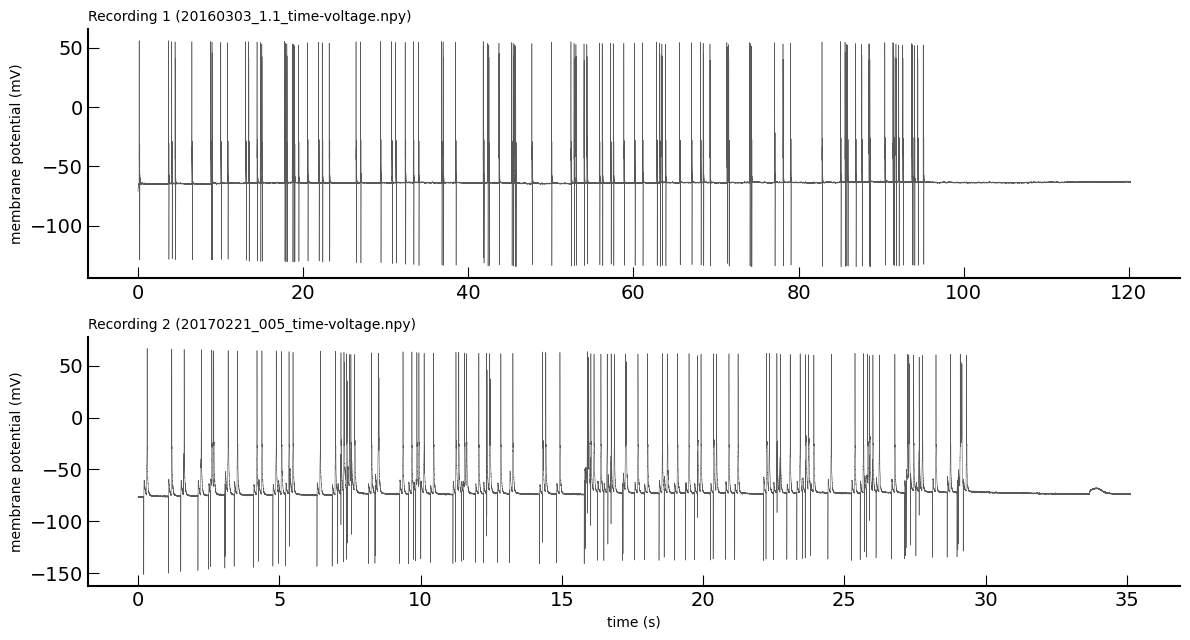

In [4]:
# overview of both recordings
fig, axs = plt.subplots(2, 1, figsize=(12, 6.5))
for ax, (name, rec) in zip(axs, recordings.items()):
    ax.plot(rec['time'], rec['vm'], color=cTrace, lw=0.4)
    ax.set_title(f"{name} ({rec['file']})", loc='left', fontsize=10)
    ax.set_ylabel('membrane potential (mV)')
axs[1].set_xlabel('time (s)')
fig.tight_layout()
plt.show()

**Figure 1 - Raw membrane potential recordings.** Whole-cell current-clamp recordings of two MSNs during an STDP protocol. Upward deflections reaching above 0 mV are postsynaptic action potentials. Downward deflections reaching below -90 mV are the artifacts of the cortical stimulation. The pairing protocol occupies the first ~95 s of recording 1 and the first ~29 s of recording 2. Events are *not* evenly spaced in time : they come irregularly, sometimes in clusters.

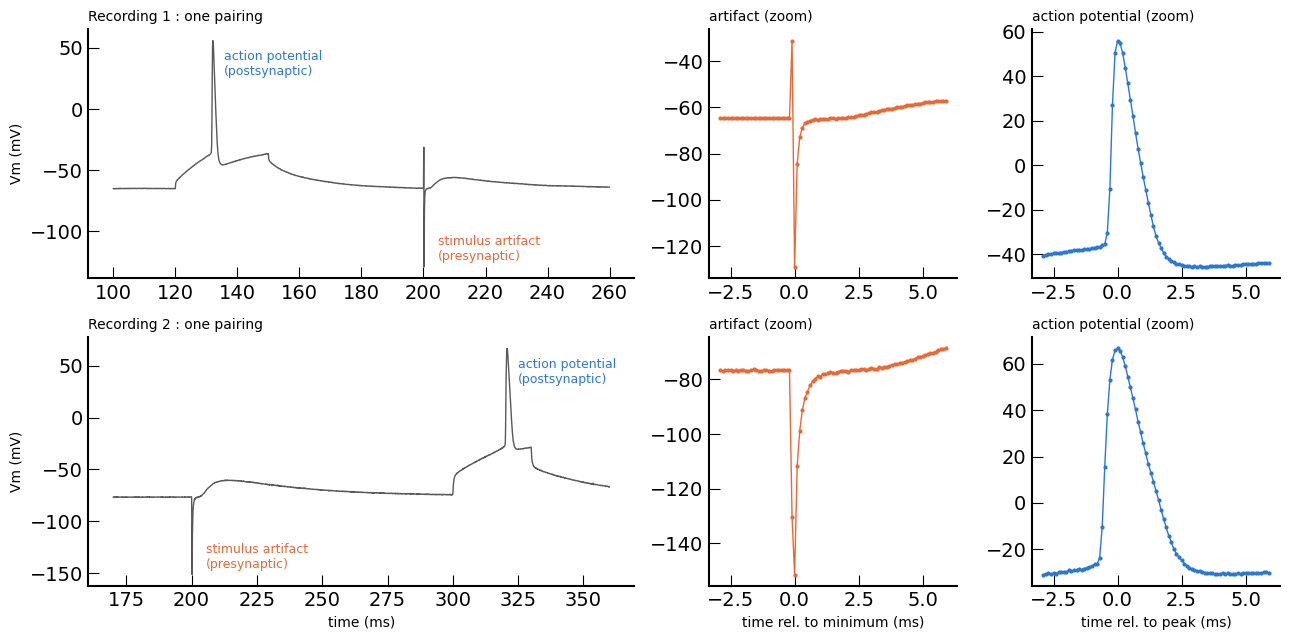

In [5]:
# zoom into a single pairing event of each recording
# (windows chosen after visual inspection of Figure 1 with `%matplotlib qt`)
zoomWindows = {'Recording 1' : (0.10, 0.26),     # s
               'Recording 2' : (0.17, 0.36)}

fig, axs = plt.subplots(2, 3, figsize=(13, 6.5), gridspec_kw={'width_ratios': [2.2, 1, 1]})
for row, (name, rec) in enumerate(recordings.items()):
    t, vm = rec['time'], rec['vm']
    t0, t1 = zoomWindows[name]
    sel = (t >= t0) & (t <= t1)
    tArtifact = t[sel][np.argmin(vm[sel])]   # time of the most negative point = artifact
    tAP       = t[sel][np.argmax(vm[sel])]   # time of the most positive point  = action potential peak

    # left : the full pairing event
    ax = axs[row, 0]
    ax.plot(t[sel]*1000, vm[sel], color=cTrace, lw=1)
    ax.annotate('stimulus artifact\n(presynaptic)', xy=(tArtifact*1000, vm[sel].min()),
                xytext=(10, 5), textcoords='offset points', color=cPre, fontsize=9)
    ax.annotate('action potential\n(postsynaptic)', xy=(tAP*1000, vm[sel].max()),
                xytext=(8, -25), textcoords='offset points', color=cPost, fontsize=9)
    ax.set_title(f'{name} : one pairing', loc='left', fontsize=10)
    ax.set_ylabel('Vm (mV)')

    # middle and right : millisecond zooms on the artifact and on the action potential
    for ax, tc, col, lab in [(axs[row, 1], tArtifact, cPre, 'artifact'),
                             (axs[row, 2], tAP, cPost, 'action potential')]:
        s2 = (t >= tc - 0.003) & (t <= tc + 0.006)
        ax.plot((t[s2] - tc)*1000, vm[s2], '.-', color=col, ms=3, lw=1)
        ax.set_title(f'{lab} (zoom)', loc='left', fontsize=10)
for ax in axs[1]:
    ax.set_xlabel('time (ms)')
axs[1, 1].set_xlabel('time rel. to minimum (ms)')
axs[1, 2].set_xlabel('time rel. to peak (ms)')
fig.tight_layout()
plt.show()

**Figure 2 - Anatomy of a single pairing.** *Left* : one pre/post pairing per recording. *Middle* : the stimulus artifact is a very brief (< 0.5 ms, i.e. a few samples) negative deflection, followed by a small positive rebound which stays well below 0 mV, and by a subthreshold EPSP. *Right* : the action potential overshoots to +40-60 mV and lasts about 1-2 ms. In both recordings the action potential is evoked by a ~30 ms depolarizing current step injected through the patch pipette (the step is visible as a sudden jump of $V_m$). In recording 1 the step starts ~80 ms *before* the cortical stimulation, and the action potential precedes the stimulation by roughly 70 ms (**post-pre** pairing). In recording 2 the step starts ~100 ms *after* the stimulation, and the action potential follows the stimulation by roughly 120 ms (**pre-post** pairing).

**First visual estimates.** Counting events in Figure 1 gives on the order of 100 stimulations and 100-150 action potentials in ~95 s (recording 1) and ~30 s (recording 2), i.e. firing rates of the order of 1-5 Hz. Because the two kinds of events have opposite polarity and very large amplitudes, a simple threshold on positive peaks (action potentials) and on negative peaks (artifacts) should separate them reliably.

### Analysis : How to extract the times of peaks (or troughs)

The function `scipy.signal.find_peaks()` seems suited to extract the timing of local peaks in a time series. See [this website](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.find_peaks.html) for more details. 

<div class="alert alert-info">Adapt the code for the project. In other words, start from the scratch, internet, tutorial code and adapt it  
    
* Change the values and fill in the project specifics. 
* It is useful and good practise to separate **computations**: the actual implementation of the analysis and **visualization** : the figure generation. 
</span>


In [6]:
# --- computation : detection functions ------------------------------------------------

def detect_post_spikes(time, vm, threshold=0., minDistance=0.002):
    '''Return the indices of postsynaptic action potentials = POSITIVE peaks of the
    membrane potential exceeding `threshold` (mV). Peaks closer than `minDistance` (s)
    are merged (keeps the largest), which avoids double detections within one spike.'''
    distance = int(round(minDistance / np.mean(np.diff(time))))   # in samples
    idx, _ = scipy.signal.find_peaks(vm, height=threshold, distance=distance)
    return idx

def detect_pre_stimuli(time, vm, threshold=-80., minDistance=0.002):
    '''Return the indices of presynaptic stimulations = NEGATIVE peaks of the membrane
    potential (stimulus artifacts) going below `threshold` (mV).
    find_peaks only finds maxima, therefore we search for peaks in -vm.'''
    distance = int(round(minDistance / np.mean(np.diff(time))))
    idx, _ = scipy.signal.find_peaks(-vm, height=-threshold, distance=distance)
    return idx

postThreshold = 0.     # mV : action potentials overshoot 0 mV, artifact rebound and EPSPs do not
preThreshold  = -80.   # mV : artifacts go below -90 mV, the physiological Vm never does


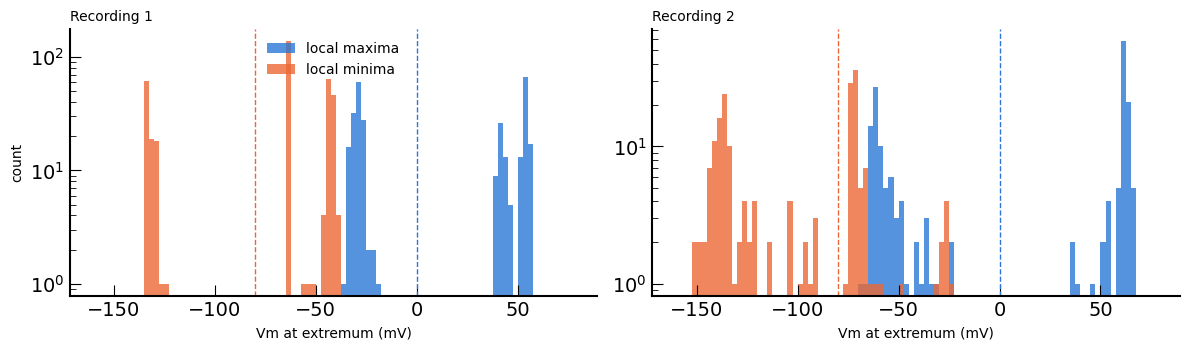

In [7]:
# --- justify the thresholds : amplitude distribution of ALL prominent local extrema ---
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, (name, rec) in zip(axs, recordings.items()):
    maxIdx, _ = scipy.signal.find_peaks(rec['vm'], prominence=10)    # all local maxima > 10 mV prominence
    minIdx, _ = scipy.signal.find_peaks(-rec['vm'], prominence=10)   # all local minima > 10 mV prominence
    bins = np.arange(-160, 80, 2.5)
    ax.hist(rec['vm'][maxIdx], bins, color=cPost, alpha=0.8, label='local maxima')
    ax.hist(rec['vm'][minIdx], bins, color=cPre, alpha=0.8, label='local minima')
    ax.axvline(postThreshold, color=cPost, ls='--', lw=1)
    ax.axvline(preThreshold, color=cPre, ls='--', lw=1)
    ax.set_title(name, loc='left', fontsize=10)
    ax.set_xlabel('Vm at extremum (mV)')
    ax.set_yscale('log')
axs[0].set_ylabel('count')
axs[0].legend(frameon=False, loc='upper center')
fig.tight_layout()
plt.show()

**Figure 3 - Choice of detection thresholds.** Distribution of the membrane potential at all prominent (> 10 mV) local maxima (blue) and minima (orange), log scale. The action potential peaks form a separate cluster above +35 mV, and the stimulus artifacts lie below -90 mV. All other extrema (artifact rebounds, EPSPs, current-step transients, resting fluctuations) lie between -76 and -18 mV. The dashed lines show the chosen thresholds (0 mV for post, -80 mV for pre). They fall in empty gaps of the distributions, so the detection does not depend on their exact values. Note that for the artifacts of recording 2 the gap is narrow (-91.7 mV for the shallowest artifact vs. -75.1 mV for the deepest non-artifact minimum), so here the threshold has to be chosen with care.

In [8]:
# --- computation : run the detection on both recordings ---------------------------------
for name, rec in recordings.items():
    rec['postIdx'] = detect_post_spikes(rec['time'], rec['vm'], postThreshold)
    rec['preIdx']  = detect_pre_stimuli(rec['time'], rec['vm'], preThreshold)
    rec['postSpikes'] = rec['time'][rec['postIdx']]    # postsynaptic spike times (s)
    rec['preSpikes']  = rec['time'][rec['preIdx']]     # presynaptic stimulation times (s)
    print(f"{name} : {len(rec['preSpikes'])} presynaptic stimulations, "
          f"{len(rec['postSpikes'])} postsynaptic action potentials")


Recording 1 : 100 presynaptic stimulations, 150 postsynaptic action potentials
Recording 2 : 100 presynaptic stimulations, 99 postsynaptic action potentials


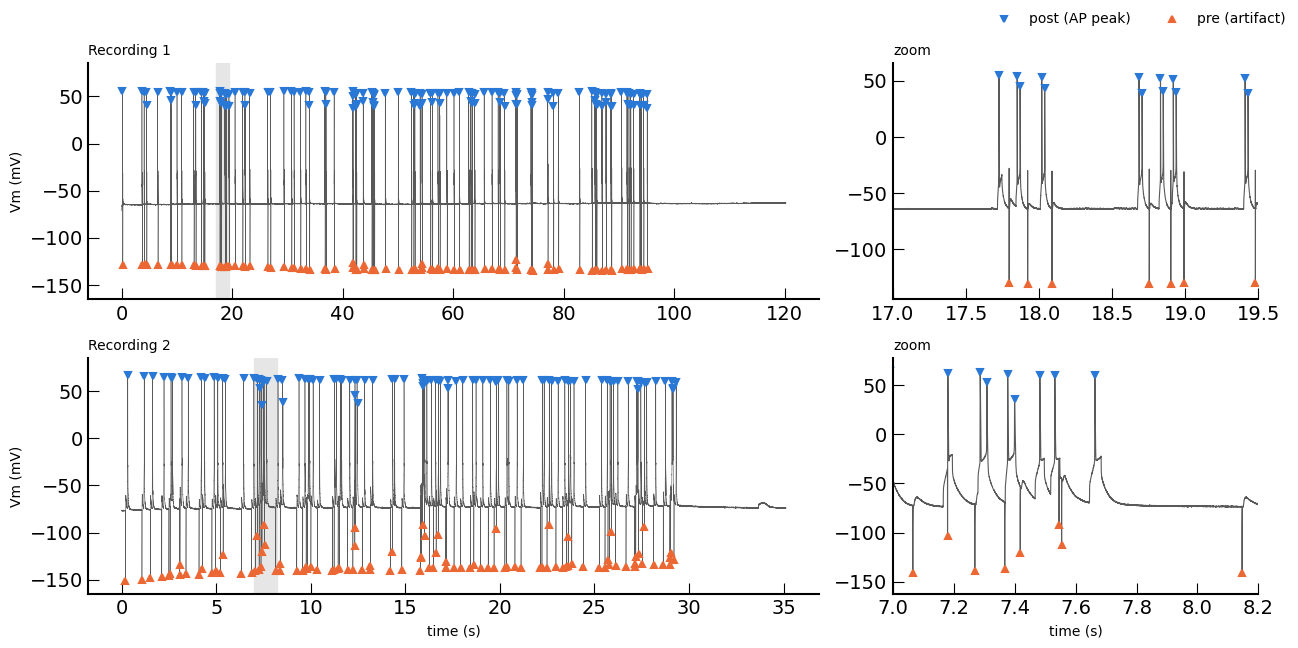

In [9]:
# --- visualization : detected events on top of the traces -------------------------------
detZoom = {'Recording 1' : (17.0, 19.5), 'Recording 2' : (7.0, 8.2)}   # s, zoom windows

fig, axs = plt.subplots(2, 2, figsize=(13, 6.5), gridspec_kw={'width_ratios': [2, 1]})
for row, (name, rec) in enumerate(recordings.items()):
    t, vm = rec['time'], rec['vm']
    for col, ax in enumerate(axs[row]):
        if col == 1:
            t0, t1 = detZoom[name]
            s = (t >= t0) & (t <= t1)
        else:
            s = slice(None)
        ax.plot(t[s], vm[s], color=cTrace, lw=0.4 if col == 0 else 0.8)
        ax.plot(t[rec['postIdx']], vm[rec['postIdx']], 'v', color=cPost, ms=5, label='post (AP peak)')
        ax.plot(t[rec['preIdx']],  vm[rec['preIdx']],  '^', color=cPre,  ms=5, label='pre (artifact)')
        if col == 1:
            ax.set_xlim(t0, t1)
            ax.set_title('zoom', loc='left', fontsize=10)
        else:
            ax.set_title(name, loc='left', fontsize=10)
            ax.axvspan(*detZoom[name], color='0.9', zorder=-1)
    axs[row, 0].set_ylabel('Vm (mV)')
    axs[row, 0].set_ylim(-165, 85)
fig.legend(*axs[0, 0].get_legend_handles_labels(), frameon=False, ncol=2, loc='upper right')
for ax in axs[1]:
    ax.set_xlabel('time (s)')
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

**Figure 4 - Detected events.** Postsynaptic action potentials (blue, positive peaks > 0 mV) and presynaptic stimulations (orange, negative peaks < -80 mV) on the raw traces (left). The gray band marks the window enlarged on the right. Every artifact and every action potential is detected exactly once. Some stimulations follow each other within a few ms to tens of ms; with the 2 ms minimal peak distance they are still counted as separate events. In recording 1 several pairings contain **two** postsynaptic spikes (a doublet ~20 ms apart).

### Firing rates and coefficient of variation

The firing rate is the number of events divided by the observation time. I report it for the whole recording and for the period of the pairing protocol (from the first to the last stimulation; the cell is silent afterwards). The CV is computed from the inter-event intervals.

In [10]:
# --- computation : spike-train statistics --------------------------------------------------

def spike_train_stats(spikeTimes, tStart, tEnd):
    '''Mean firing rate (Hz) in [tStart, tEnd], ISIs (s) and CV of the ISIs.'''
    isi  = np.diff(spikeTimes)
    rate = np.sum((spikeTimes >= tStart) & (spikeTimes <= tEnd)) / (tEnd - tStart)
    cv   = np.std(isi) / np.mean(isi)
    return rate, isi, cv

print(f"{'':12s} {'train':5s} {'N':>4s} {'rate total':>11s} {'rate protocol':>14s} {'mean ISI':>9s} {'CV':>6s}")
for name, rec in recordings.items():
    # protocol period : first to last presynaptic stimulation (+ 0.2 s margin to include spikes after the last stimulation)
    tP0 = min(rec['preSpikes'][0], rec['postSpikes'][0])
    tP1 = max(rec['preSpikes'][-1], rec['postSpikes'][-1])
    rec['protocol'] = (tP0, tP1)
    for train in ['pre', 'post']:
        st = rec[train + 'Spikes']
        rTot, isi, cv = spike_train_stats(st, rec['time'][0], rec['time'][-1])
        rProt, _, _   = spike_train_stats(st, tP0, tP1)
        rec[train + 'Stats'] = {'rateTotal': rTot, 'rateProtocol': rProt, 'isi': isi, 'cv': cv}
        print(f"{name:12s} {train:5s} {len(st):4d} {rTot:8.2f} Hz {rProt:11.2f} Hz {np.mean(isi)*1000:6.0f} ms {cv:6.2f}")


             train    N  rate total  rate protocol  mean ISI     CV
Recording 1  pre    100     0.83 Hz        1.05 Hz    959 ms   0.95
Recording 1  post   150     1.25 Hz        1.58 Hz    638 ms   1.35
Recording 2  pre    100     2.85 Hz        3.43 Hz    293 ms   0.87
Recording 2  post    99     2.82 Hz        3.40 Hz    296 ms   0.85


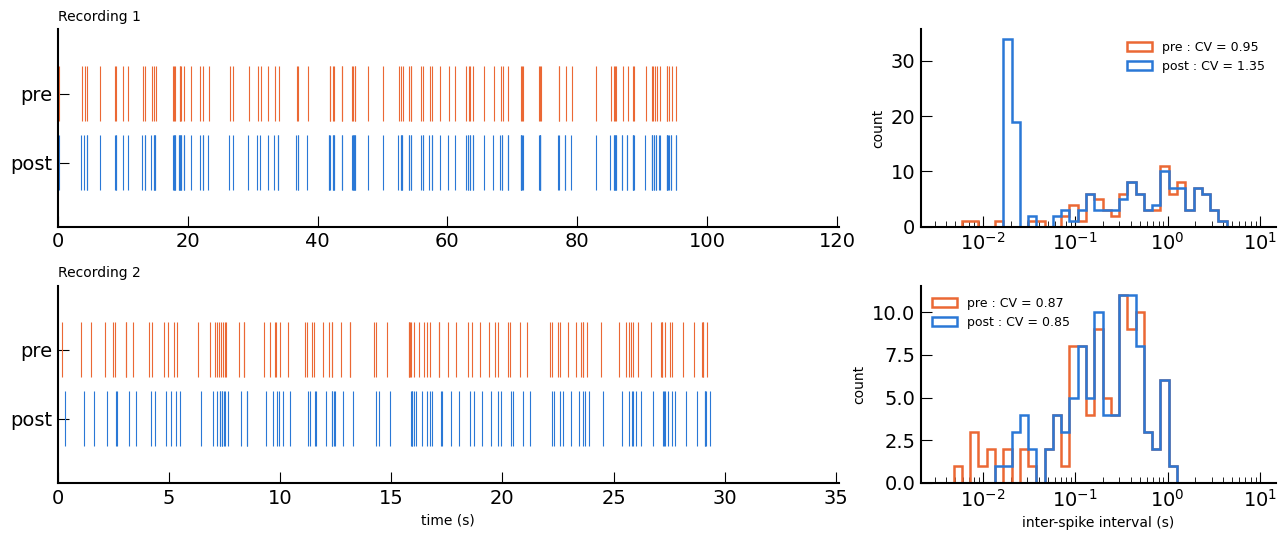

In [11]:
# --- visualization : raster plots and ISI distributions ---------------------------------
fig, axs = plt.subplots(2, 2, figsize=(13, 5.5), gridspec_kw={'width_ratios': [2.2, 1]})
isiBins = np.logspace(-2.5, 1, 40)     # logarithmic ISI bins from ~3 ms to 10 s
for row, (name, rec) in enumerate(recordings.items()):
    ax = axs[row, 0]
    ax.eventplot([rec['postSpikes'], rec['preSpikes']], colors=[cPost, cPre],
                 lineoffsets=[0, 1], linelengths=0.8, linewidths=0.8)
    ax.set_yticks([0, 1], ['post', 'pre'])
    ax.set_xlim(rec['time'][0], rec['time'][-1])
    ax.set_title(name, loc='left', fontsize=10)

    ax = axs[row, 1]
    for train, col in [('pre', cPre), ('post', cPost)]:
        s = rec[train + 'Stats']
        ax.hist(s['isi'], isiBins, histtype='step', color=col, lw=1.8,
                label=f"{train} : CV = {s['cv']:.2f}")
    ax.set_xscale('log')
    ax.set_ylabel('count')
    ax.legend(frameon=False, fontsize=9)
axs[1, 0].set_xlabel('time (s)')
axs[1, 1].set_xlabel('inter-spike interval (s)')
fig.tight_layout()
plt.show()

**Figure 5 - Spike trains and their regularity.** *Left* : raster plots of presynaptic stimulations (orange) and postsynaptic action potentials (blue). *Right* : ISI distributions on a logarithmic axis. The stimulations are delivered at irregular intervals : the CV is close to 1 (0.95 and 0.87), as for a Poisson process. The mean interval is ~1 s (≈ 1 Hz, recording 1) and ~0.3 s (≈ 3.4 Hz, recording 2). The postsynaptic train of recording 1 has CV ≈ 1.35, i.e. it is *burstier* than Poisson. This comes from the doublets : the peak at ~20 ms in its ISI distribution is the within-doublet interval. In recording 2 the postsynaptic ISI statistics closely follow the presynaptic ones, because each stimulation is followed by exactly one postsynaptic spike.

<div class="alert alert-info">Sometimes, the analysis can take minutes or even hours, when the data-set is large or the computations heavy. Be patient. You can try to let the analysis run over night.</div>

**Figure generation**
Show your results in figure with captions and labels.

<div class="alert alert-info">Producing good representations of results in form of figures takes time and effort. Try to find the visualization which best conveys your result. Certain measures have standard representations (e.g. frequency content is shown in spectrograms, spikes in raster plots, etc.).</div>

### Example code to calculate cross-correlogram 

In the code below, the pre- and postsynaptic spike time are constructed. In the loop all time differences between pre- and postsynaptic spike times are calculated. The histogram of those time differences gives information about the delay between pre- and postsynpatic spikes. 

In [12]:
# toy example : 100 presynaptic events at random times in 8 s, each followed by a
# postsynaptic event exactly 35 ms later
np.random.seed(1)
tpre  = np.sort(np.random.random(100) * 8)
tpost = tpre + 0.035

In [13]:
tpre[:10]

array([0.000915  , 0.02296262, 0.14630622, 0.15493566, 0.21910075,
       0.31243827, 0.39962767, 0.42690036, 0.68035369, 0.73870876])

In [14]:
tpost[:10]

array([0.035915  , 0.05796262, 0.18130622, 0.18993566, 0.25410075,
       0.34743827, 0.43462767, 0.46190036, 0.71535369, 0.77370876])

In [15]:
# --- computation : cross-correlogram --------------------------------------------------------

def cross_correlogram(preTimes, postTimes, window=0.5, binWidth=0.002):
    '''Histogram of all time differences  t_post - t_pre  within +/- window (s).
    Returns the raw differences, the counts per bin and the bin edges.'''
    allDeltaTs = []
    for i in np.arange(len(preTimes)):
        deltaT = postTimes - preTimes[i]                 # all post spikes relative to the i-th pre spike
        allDeltaTs.extend(deltaT[np.abs(deltaT) <= window])
    allDeltaTs = np.array(allDeltaTs)
    edges = np.arange(-window, window + binWidth / 2, binWidth)
    counts, _ = np.histogram(allDeltaTs, edges)
    return allDeltaTs, counts, edges

toyDeltaTs, toyCounts, toyEdges = cross_correlogram(tpre, tpost, window=1.0, binWidth=0.005)


In [16]:
# number of time differences computed by the loop (before restricting to the window)
len(tpre) * len(tpost)

10000

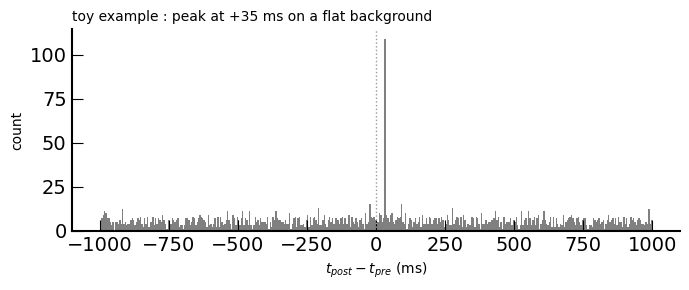

In [17]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(toyEdges[:-1]*1000, toyCounts, width=np.diff(toyEdges)*1000, align='edge', color='0.5')
ax.axvline(0, color='0.6', ls=':', lw=1)
ax.set_xlabel(r'$t_{post} - t_{pre}$ (ms)')
ax.set_ylabel('count')
ax.set_title('toy example : peak at +35 ms on a flat background', loc='left', fontsize=10)
fig.tight_layout()
plt.show()

**Figure 6 - Cross-correlogram of the toy example.** The 100 "true" pairs all fall into the bin containing +35 ms. All other combinations (a pre spike with an unrelated post spike) give a flat background, because the toy events are random in time. The height of the background depends on the event rates, the bin width and the number of events.

### Cross-correlograms of the recorded neurons and extraction of $\Delta t$

The same function is now applied to the detected pre- and postsynaptic spike times. $\Delta t$ is extracted in two steps :
1. **CCG peak** : the center of the most populated bin of the cross-correlogram (1 ms bins) gives a first estimate of $\Delta t$.
2. **Per-pairing $\Delta t$** : for every presynaptic stimulation, take the postsynaptic spike closest to the CCG peak, within ±25 ms of it. This gives one $\Delta t$ value per pairing, from which mean, standard deviation and median follow.

In [18]:
# --- computation : CCG and Delta t for both recordings -----------------------------------
binWidth = 0.001      # 1 ms
window   = 0.5        # +/- 500 ms
searchWindow = 0.025  # +/- 25 ms around the CCG peak for the per-pairing Delta t

for name, rec in recordings.items():
    dts, counts, edges = cross_correlogram(rec['preSpikes'], rec['postSpikes'], window, binWidth)
    centers = edges[:-1] + binWidth / 2
    peakDt  = centers[np.argmax(counts)]                    # CCG peak position (s)

    # per pairing : post spike closest to the CCG peak
    pairDts = []
    for tp in rec['preSpikes']:
        d = rec['postSpikes'] - tp                          # all post spikes relative to this stimulation
        d = d[np.abs(d - peakDt) <= searchWindow]
        pairDts.append(d[np.argmin(np.abs(d - peakDt))] if len(d) > 0 else np.nan)
    pairDts = np.array(pairDts)

    rec['ccg'] = {'dts': dts, 'counts': counts, 'edges': edges, 'centers': centers, 'peak': peakDt}
    rec['pairDts'] = pairDts
    n = np.sum(~np.isnan(pairDts))
    print(f"{name} : CCG peak at {peakDt*1000:+.1f} ms ({counts.max()} counts in 1 ms bin)")
    print(f"     per pairing (n = {n}/{len(pairDts)}) : Delta t = {np.nanmean(pairDts)*1000:+.1f} +/- {np.nanstd(pairDts)*1000:.1f} ms (mean +/- SD), "
          f"median {np.nanmedian(pairDts)*1000:+.1f} ms, range [{np.nanmin(pairDts)*1000:+.1f}, {np.nanmax(pairDts)*1000:+.1f}] ms")


Recording 1 : CCG peak at -70.5 ms (62 counts in 1 ms bin)
     per pairing (n = 100/100) : Delta t = -70.6 +/- 1.5 ms (mean +/- SD), median -70.4 ms, range [-79.0, -63.2] ms
Recording 2 : CCG peak at +118.5 ms (23 counts in 1 ms bin)
     per pairing (n = 100/100) : Delta t = +116.5 +/- 4.4 ms (mean +/- SD), median +117.7 ms, range [+106.5, +130.9] ms


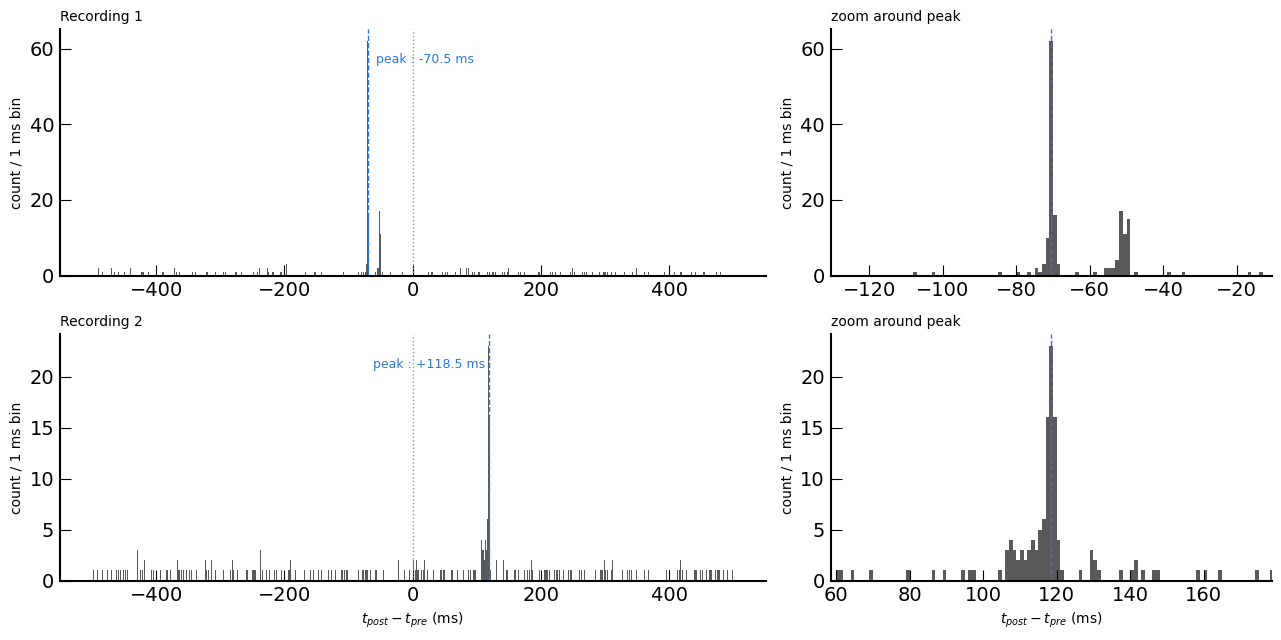

In [19]:
# --- visualization : cross-correlograms ------------------------------------------------------
fig, axs = plt.subplots(2, 2, figsize=(13, 6.5), gridspec_kw={'width_ratios': [1.6, 1]})
for row, (name, rec) in enumerate(recordings.items()):
    c = rec['ccg']
    pk = c['peak'] * 1000
    for col, ax in enumerate(axs[row]):
        ax.bar(c['edges'][:-1]*1000, c['counts'], width=binWidth*1000, align='edge', color='0.35')
        ax.axvline(0, color='0.6', ls=':', lw=1)
        ax.axvline(pk, color=cPost, ls='--', lw=1)
        if col == 1:
            ax.set_xlim(pk - 60, pk + 60)
            ax.set_title(f'zoom around peak', loc='left', fontsize=10)
        else:
            ax.set_title(f'{name}', loc='left', fontsize=10)
            ax.text(pk, c['counts'].max()*0.95, f'  peak : {pk:+.1f} ms ', color=cPost, fontsize=9, va='top',
                    ha='left' if pk < 0 else 'right')
        ax.set_ylabel('count / 1 ms bin')
for ax in axs[1]:
    ax.set_xlabel(r'$t_{post} - t_{pre}$ (ms)')
fig.tight_layout()
plt.show()

**Figure 7 - Cross-correlograms between presynaptic stimulations and postsynaptic action potentials** (1 ms bins, ±500 ms). Both recordings show a single dominant peak on a low, roughly flat background. *Recording 1* : the peak is at **negative** lags (-70.5 ms) : the postsynaptic spike precedes the stimulation, a **post-pre** protocol. A second, smaller peak at ≈ -50 ms comes from the second spike of the postsynaptic doublets. *Recording 2* : the peak is at **positive** lags (+118.5 ms) : the stimulation precedes the postsynaptic spike, a **pre-post** protocol. Its peak is broader than in recording 1 (see below).

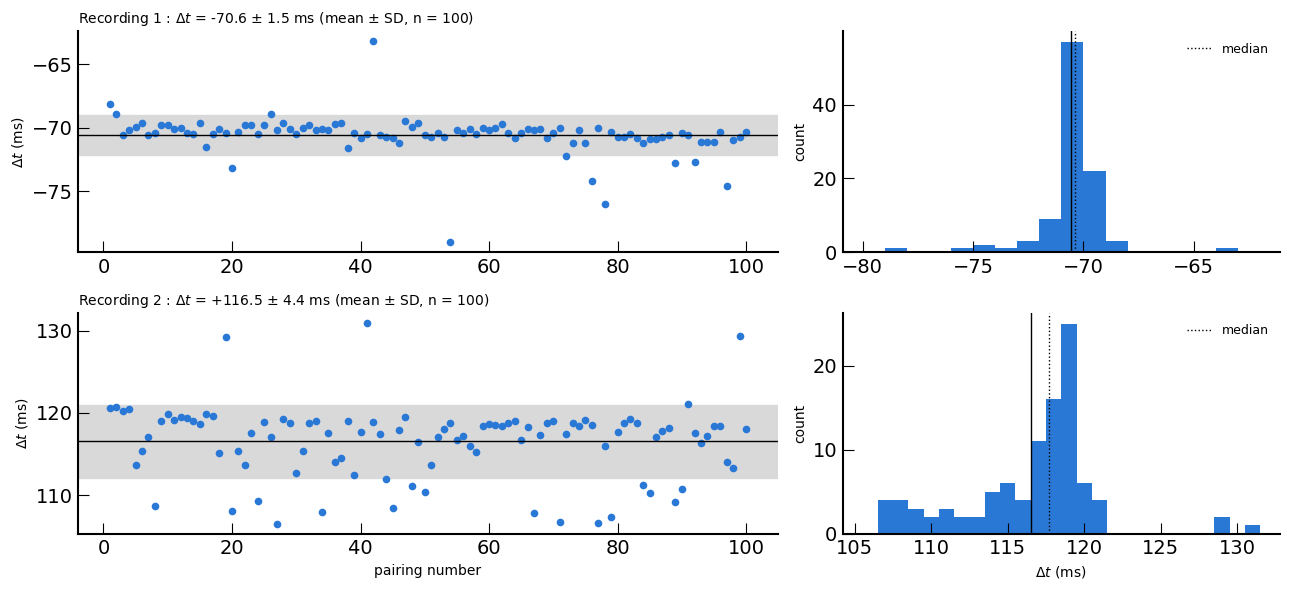

In [20]:
# --- visualization : per-pairing Delta t ------------------------------------------------------
fig, axs = plt.subplots(2, 2, figsize=(13, 6), gridspec_kw={'width_ratios': [1.6, 1]})
for row, (name, rec) in enumerate(recordings.items()):
    d = rec['pairDts'] * 1000
    m, s = np.nanmean(d), np.nanstd(d)
    ax = axs[row, 0]
    ax.plot(np.arange(1, len(d)+1), d, 'o', color=cPost, ms=4)
    ax.axhline(m, color='k', lw=1)
    ax.axhspan(m - s, m + s, color='0.85', zorder=-1)
    ax.set_ylabel(r'$\Delta t$ (ms)')
    ax.set_title(f'{name} : $\\Delta t$ = {m:+.1f} ± {s:.1f} ms (mean ± SD, n = {np.sum(~np.isnan(d))})',
                 loc='left', fontsize=10)
    ax = axs[row, 1]
    ax.hist(d, bins=np.arange(np.nanmin(d)-1, np.nanmax(d)+1.5, 1), color=cPost)
    ax.axvline(m, color='k', lw=1)
    ax.axvline(np.nanmedian(d), color='k', ls=':', lw=1, label='median')
    ax.set_ylabel('count')
    ax.legend(frameon=False, fontsize=9)
axs[1, 0].set_xlabel('pairing number')
axs[1, 1].set_xlabel(r'$\Delta t$ (ms)')
fig.tight_layout()
plt.show()

**Figure 8 - $\Delta t$ of each pairing.** *Left* : $\Delta t$ for every presynaptic stimulation, in temporal order (black line : mean, gray band : ±1 SD). *Right* : distribution. Every one of the 100 stimulations in each recording has a postsynaptic partner spike near the CCG peak.
* **Recording 1** : $\Delta t = -70.6 \pm 1.5$ ms (median -70.4 ms), a **post-pre** protocol. Timing is very precise and stable over the whole protocol; only a few pairings deviate by more than a few ms.
* **Recording 2** : $\Delta t = +116.5 \pm 4.4$ ms (median +117.7 ms), a **pre-post** protocol. Most pairings lie at 117–121 ms, and a group of pairings lies at 106–114 ms (plus a few at ~130 ms). There is no slow drift over the protocol; the deviations are scattered. Where do they come from? See the next section.

**Further analysis and interpretation of results**

The main result is $\Delta t$ for both recordings. Three questions follow : (i) is the CCG peak really a consequence of the protocol, i.e. clearly above what we would expect by chance given the firing rates? (ii) how many postsynaptic spikes does each pairing contain (the doublets in recording 1)? (iii) why do some pairings deviate from the typical $\Delta t$? Since the stimulations are irregular and sometimes only a few ms apart, one candidate is the interval to the neighboring stimulation.

<div class="alert alert-info">Going an additional step after obtaining the main result provides often great insight, doesn't take much effort and increases the quality/impact of your work.</div>

In [21]:
# --- computation : surrogate (shuffled) cross-correlograms ---------------------------------
# Null hypothesis : pre and post trains have the observed numbers of events but no temporal
# relation. Surrogate presynaptic trains are generated by drawing the same number of
# stimulation times uniformly within the protocol period; the CCG is recomputed each time.
nSurrogates = 500
rng = np.random.default_rng(2026)
for name, rec in recordings.items():
    tP0, tP1 = rec['protocol']
    nPre = len(rec['preSpikes'])
    surr = np.zeros((nSurrogates, len(rec['ccg']['counts'])))
    for k in range(nSurrogates):
        fakePre = np.sort(rng.uniform(tP0, tP1, nPre))
        _, surr[k], _ = cross_correlogram(fakePre, rec['postSpikes'], window, binWidth)
    rec['surr'] = {'mean': surr.mean(0), 'max': surr.max()}   # mean CCG and largest bin over all surrogates
    z = (rec['ccg']['counts'].max() - surr.mean()) / surr.std()
    print(f"{name} : surrogate CCG {surr.mean():.2f} +/- {surr.std():.2f} counts/bin, "
          f"largest surrogate bin = {surr.max():.0f}, observed peak = {rec['ccg']['counts'].max()} (z = {z:.0f})")


Recording 1 : surrogate CCG 0.16 +/- 0.40 counts/bin, largest surrogate bin = 4, observed peak = 62 (z = 157)
Recording 2 : surrogate CCG 0.33 +/- 0.58 counts/bin, largest surrogate bin = 5, observed peak = 23 (z = 39)


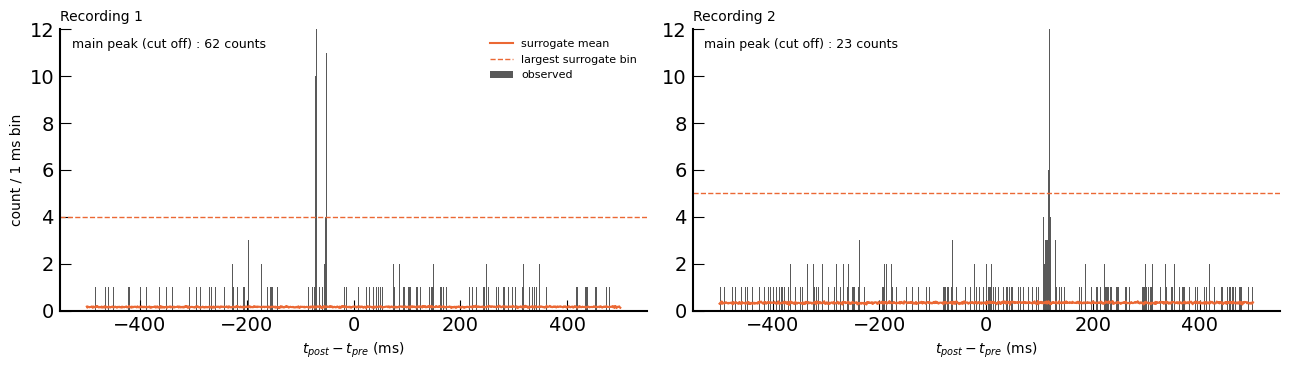

In [22]:
# --- visualization : observed vs. surrogate cross-correlograms ------------------------------
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (name, rec) in zip(axs, recordings.items()):
    c = rec['ccg']
    ax.bar(c['edges'][:-1]*1000, c['counts'], width=binWidth*1000, align='edge', color='0.35', label='observed')
    ax.plot(c['centers']*1000, rec['surr']['mean'], color=cPre, lw=1.5, label='surrogate mean')
    ax.axhline(rec['surr']['max'], color=cPre, lw=1, ls='--', label='largest surrogate bin')
    ax.set_title(name, loc='left', fontsize=10)
    ax.set_xlabel(r'$t_{post} - t_{pre}$ (ms)')
    ax.set_ylim(0, 12)
    ax.text(0.02, 0.97, f"main peak (cut off) : {c['counts'].max()} counts", transform=ax.transAxes, va='top', fontsize=9)
axs[0].set_ylabel('count / 1 ms bin')
axs[0].legend(frameon=False, fontsize=8, loc='upper right')
fig.tight_layout()
plt.show()

**Figure 9 - Significance of the CCG peak.** Observed CCGs (gray; y-axis cut at 12 counts to show the background) compared with 500 surrogate CCGs. For each surrogate, the same number of stimulations was placed at random times within the protocol (orange : mean surrogate CCG and the largest bin found in any of the 500 surrogates). Away from the peaks, the observed CCG matches the chance level of a few coincidences per bin. The main peak (62 and 23 counts per 1 ms bin) is far above the largest bin of any surrogate (4 and 5 counts; z-scores of ~160 and ~40). The pre-post relation is therefore produced by the protocol and is not a chance coincidence due to the firing rates. In recording 1 the doublet peak at ≈ -50 ms is also significant.

**Discussion**

<div class="alert alert-info">Finish with a disucssion which contains a summary of your results and an interpretation. What does it mean? What would be further steps?</div>

### Summary of results

| | Recording 1 (20160303_1.1) | Recording 2 (20170221_005) |
|---|---|---|
| duration (protocol) | 120 s (≈ 95 s) | 35 s (≈ 29 s) |
| presynaptic stimulations | 100 | 100 |
| postsynaptic action potentials | 150 | 99 |
| pre rate during protocol | ≈ 1.05 Hz | ≈ 3.4 Hz |
| post rate during protocol | ≈ 1.6 Hz | ≈ 3.4 Hz |
| CV pre / post | 0.95 / 1.35 | 0.87 / 0.85 |
| post spikes per pairing | 1 (50 pairings) or 2 (50 pairings) | 1 |
| CCG peak | -70.5 ms | +118.5 ms |
| **$\Delta t$, all pairings (mean ± SD, n = 100)** | **-70.6 ± 1.5 ms** (median -70.4 ms) | **+116.5 ± 4.4 ms** (median +117.7 ms) |
| **$\Delta t$, isolated pairings** | **-70.3 ± 0.5 ms** (n = 72) | **+119.0 ± 0.7 ms** (n = 40) |
| protocol type | **post-pre** | **pre-post** |

### Discussion

**Event detection.** Presynaptic stimulations and postsynaptic action potentials can be extracted from a single membrane potential trace because the two have opposite polarity and very different amplitudes. The stimulus artifacts are sharp negative transients below -90 mV. The action potentials overshoot to +35–65 mV. Both clusters are well separated from all other fluctuations (Figure 3), so simple thresholds with `scipy.signal.find_peaks` detect them without ambiguity. One caveat about timing : the post-spike time is taken at the AP *peak*, which lags the AP onset (threshold crossing) by ~1 ms. The artifact minimum, by contrast, marks the stimulation time to within a sample. This shifts all $\Delta t$ by ~1 ms, which is negligible compared to the values measured here.

**Firing statistics.** The presynaptic stimulations are delivered at irregular times with CV ≈ 0.9, i.e. close to a Poisson process. The mean rate is ≈ 1 Hz in recording 1 and ≈ 3.4 Hz in recording 2. This differs from the regular 1 Hz pairings described in Paille et al. 2013. The postsynaptic neuron does not fire spontaneously : apart from the evoked spikes there are no action potentials (flat CCG background, nothing after the end of the protocol). Its spike train simply mirrors the stimulation schedule. In recording 2 this gives the same CV as the presynaptic train. In recording 1 the doublets (second spike ~20 ms after the first in 50 % of the pairings) give a CV > 1.

**Cross-correlogram and $\Delta t$.** Both cross-correlograms have one dominant, highly significant peak, which identifies the pairing protocol directly from the data :
* Recording 1 is a **post-pre** protocol with $\Delta t = -70.6 \pm 1.5$ ms. Half of the pairings contain a postsynaptic doublet, whose second spike falls at $\Delta t \approx -50$ ms.
* Recording 2 is a **pre-post** protocol with $\Delta t = +116.5 \pm 4.4$ ms (median +117.7 ms).

The spread of $\Delta t$ is not random jitter of the protocol. Isolated pairings have an almost constant delay (-70.3 ± 0.5 ms and +119.0 ± 0.7 ms; Figure 10). All larger deviations occur when another stimulation falls within ~150 ms. In that case it can be ambiguous which spike belongs to which stimulation. In recording 2, the EPSP of a preceding stimulation can also depolarize the cell and advance the spike evoked by the current step. For an STDP study, the isolated-pairing values are the best estimate of the *intended* $\Delta t$, while the full distribution describes the timing the synapse actually *experienced*. With irregular stimulation, a synapse also sees additional pre/post spike pairs at other time differences (CCG background and doublet peak). These may contribute to plasticity as well.

Both $|\Delta t|$ values are much larger than the ±30 ms window that Paille et al. 2013 used to induce LTP (post-pre) and LTD (pre-post). With classical STDP learning windows, which decay within a few tens of ms, one would expect little plasticity at such long intervals. Whether and in which direction these synapses changed cannot be decided from these traces : it would require the EPSC/EPSP amplitudes before and after the protocol.

**Limitations and further steps.**
* Only two cells are analyzed, so the numbers describe these recordings and cannot be generalized.
* The threshold values are recording-specific. For other cells (e.g. smaller artifacts or APs with less overshoot) they should be checked with a histogram like Figure 3, or replaced by an adaptive criterion (e.g. prominence or derivative-based detection; AP onset from the $dV/dt$ threshold instead of the peak).
* Physiological extensions : measure the EPSP amplitude after each stimulation to follow synaptic efficacy *during* the protocol; test whether the subthreshold depolarization before the current step explains the earlier spikes in closely spaced pairings of recording 2; analyze AP waveform changes along the protocol.
* Plasticity outcome : combined with the baseline and post-protocol EPSC recordings, the extracted $\Delta t$ values could be placed on the STDP curve of Paille et al. 2013 for comparison.
